In [165]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
import numpy.ma as ma
from scipy import ndimage


import sys
sys.path.insert(1, '/Users/nityaravi/Documents/GitHub/RotationCurves/spirals/')

from DRP_rotation_curve import extract_data
from DRP_vel_map_functions import find_phi, deproject_spaxel

In [154]:
H_0 = 100      # Hubble's Constant in units of h km/s/Mpc
c = 299792.458 # Speed of light in units of km/s

MANGA_SPAXEL_SIZE = 0.5*(1/60)*(1/60)*(np.pi/180)  # spaxel size (0.5") in radians
q0 = 0.2


In [2]:
MANGA_FOLDER = '/Users/nityaravi/Documents/Research/RotationCurves/data/manga/'
VEL_MAP_FOLDER = MANGA_FOLDER + 'DR17/'

DRP_table_fn = MANGA_FOLDER + '/output_files/DR17/CURRENT_MASTER_TABLE/Elliptical_sphdisk_refitspirals_BPT_illustris_v11.fits'

In [3]:
DRP_table = Table.read(DRP_table_fn)

In [4]:
morph_fn = MANGA_FOLDER + '/manga-morphology-dl-DR17.fits'
morph = Table.read(morph_fn)

In [5]:
morph[:5]

INTID,MANGA_ID,PLATEIFU,OBJID,RA,DEC,Z,DUPL_GR,DUPL_N,DUPL_ID,T-Type,T-Type_std,P_LTG,P_LTG_std,P_S0,P_S0_std,P_edge,P_edge_std,P_bar,P_bar_std,Visual_Class,Visual_Flag
int16,bytes9,bytes15,int64,float64,float64,float64,int16,int16,int16,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int16,int16
1,1-286558,8325-12701,1237661435926544550,210.17634,45.833422,0.04288710891658048,0,0,0,4.221438407897949,0.6632512920115043,0.9802886247634888,0.023341917289120134,0.938228964805603,0.12361474624591347,0.0039536390686407685,0.065356233171725,0.45846888422966003,0.065356233171725,3,0
2,1-274706,8253-12701,1237660634384761005,157.05886,42.96805,0.04496037553087202,0,0,0,4.378849506378174,1.0630811776112241,0.999234676361084,0.0012762211396711856,0.9836623072624207,0.144277846757422,0.9999891519546509,0.00016300611310054642,0.10297111421823502,0.00016300611310054642,3,0
3,1-201874,8938-12701,1237657118405886241,119.75748,30.976025,0.05276287200043103,0,0,0,3.3679091930389404,0.6427940112443938,0.927117645740509,0.12398989623522808,0.8620888590812683,0.12167109396230592,0.6124326288700104,0.146001299579978,0.16775675863027573,0.146001299579978,3,0
4,1-626658,8983-12701,1237667323264368802,203.83021,26.424781,0.02535624535944735,0,0,0,3.3002166748046875,0.7500633033353644,0.9808579385280609,0.023036707681772097,0.9125989377498627,0.1421640087995252,0.006133790244348347,0.02660665703469211,0.18608582764863968,0.02660665703469211,3,0
5,1-24425,8626-12701,1237656529994055837,263.52527,56.799613,0.02923735792806886,0,0,0,-0.22833305597305298,0.5620976832249787,0.062017541378736496,0.0343759162684501,0.2607986405491829,0.20289286953115845,0.03328006900846958,0.07390042108431057,0.157500758767128,0.07390042108431057,1,0


## add morphology info to master table

In [6]:
DRP_table[:5]

plate,ifudsgn,plateifu,mangaid,versdrp2,versdrp3,verscore,versutil,versprim,platetyp,srvymode,objra,objdec,ifuglon,ifuglat,ifura,ifudec,ebvgal,nexp,exptime,drp3qual,bluesn2,redsn2,harname,frlplug,cartid,designid,cenra,cendec,airmsmin,airmsmed,airmsmax,seemin,seemed,seemax,transmin,transmed,transmax,mjdmin,mjdmed,mjdmax,gfwhm,rfwhm,ifwhm,zfwhm,mngtarg1,mngtarg2,mngtarg3,catidnum,plttarg,manga_tileid,nsa_iauname,ifudesignsize,ifutargetsize,ifudesignwrongsize,z,zmin,zmax,szmin,szmax,ezmin,ezmax,probs,pweight,psweight,psrweight,sweight,srweight,eweight,esweight,esrweight,nsa_field,nsa_run,nsa_camcol,nsa_version,nsa_nsaid,nsa_nsaid_v1b,nsa_z,nsa_zdist,nsa_sersic_absmag,nsa_elpetro_absmag,nsa_elpetro_amivar,nsa_sersic_mass,nsa_elpetro_mass,nsa_elpetro_ba,nsa_elpetro_phi,nsa_extinction,nsa_elpetro_th50_r,nsa_petro_th50,nsa_petro_flux,nsa_petro_flux_ivar,nsa_elpetro_flux,nsa_elpetro_flux_ivar,nsa_sersic_ba,nsa_sersic_n,nsa_sersic_phi,nsa_sersic_th50,nsa_sersic_flux,nsa_sersic_flux_ivar,smoothness_score,nsa_elpetro_th90,v_sys,v_sys_err,ba,ba_err,x0,x0_err,y0,y0_err,phi,phi_err,v_max,v_max_err,r_turn,r_turn_err,chi2,alpha,alpha_err,Rmax,M,M_err,fit_flag,Sigma_disk,Sigma_disk_err,R_disk,R_disk_err,rho_bulge,rho_bulge_err,R_bulge,R_bulge_err,M90_disk,M90_disk_err,M_disk,M_disk_err,chi2_disk,WF50,WF50_err,DL_ttype,vis_tidal,b,b_err,M_R90,M_R90_err,fit_function,A_g,A_r,logH2,R90_kpc,v_3p5,v_3p5_err,NSA_plate,NSA_fiberID,NSA_MJD,logH2_CG,logH2_CG_err,logH2_M,Z,Z_err,M_Z,M_Z_err,grad_Z,grad_Z_err,Z_0,Z_0_err,SFR,sSFR,SFR_err,sSFR_err,Flux_OII_3726,Flux_OII_3726_Err,Flux_OII_3728,Flux_OII_3728_Err,Flux_OIII_4958,Flux_OIII_4958_Err,Flux_OIII_5006,Flux_OIII_5006_Err,Flux_NII_6547,Flux_NII_6547_Err,Flux_NII_6583,Flux_NII_6583_Err,Flux_Ha_6562,Flux_Ha_6562_Err,Flux_Hb_4861,Flux_Hb_4861_Err,CMD_class,rabsmag_NSA,param_H2,param_H2_err,Z_map,Z_err_map,M_Z_map,M_Z_err_map,logHI_R90,Mvir,Mvir_err,star_sigma,star_sigma_err,dipole_moment,Rgal,vflag_VF,nsa_elpetro_log_mass,rabsmag,param_H2_R90,logHe,sphd_rho_c,sphd_rho_c_err,sphd_R_scale,sphd_R_scale_err,sphd_Sigma_d,sphd_Sigma_d_err,sphd_R_d,sphd_R_d_err,sphd_M_star,sphd_M_star_err,sphd_chi2,mhq_R_scale,mhq_R_scale_err,mhq_M_star,mhq_M_star_err,mhq_gamma,mhq_gamma_err,mhq_chi2,hq_R_scale,hq_R_scale_err,hq_M_star,hq_M_star_err,hq_chi2,sph_rho_c,sph_rho_c_err,sph_R_scale,sph_R_scale_err,sph_M_star,sph_M_star_err,sph_chi2,sum_M_star,sum_M_star_err,BPT_class,spiral_mask,elliptical_mask,Age_LW_Re_fit,Age_MW_Re_fit,ZH_LW_Re_fit,ZH_MW_Re_fit,M90_disk_h,M90_disk_err_h,sphd_M_star_err_h,sphd_M_star_h,V_R90,V_R90_err,e_M_star_R90,e_M_star_R90_err,e_M_star_R90_h,e_M_star_R90_err_h,v_eff,v_eff_err,logHI,logHI_err,HI_catalog,logHI_h,logHI_err_h,N2Ha,O3Hb,nsa_u_r,illustris_match,illustris_dist,illustris_u_r,illustris_Mstar,illustris_Mstar_Sal,illustris_Vmax,illustris_flag,illustris_MR90,MH2_S14_vol,MHI_S14_vol,MHtot
int64,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,float64,bytes53,int64,bytes32,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,float64,float64,float64,float64,int64,int64,int64,int64,bytes32,int64,bytes19,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,bytes6,int64,int64,float64,float64,float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64,float64,float64[7],float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64[7],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,

In [10]:
DRP_dict = {}
for i in range(len(DRP_table)):

    DRP_dict[DRP_table['plateifu'][i]] = i

In [11]:
DRP_table['DL_ttype_err'] = np.ones(len(DRP_table))*np.nan
DRP_table['DL_P_S0'] = np.ones(len(DRP_table))*np.nan
DRP_table['DL_P_S0_err'] = np.ones(len(DRP_table))*np.nan

In [20]:
for i in range(len(morph)):

    plateifu = morph['PLATEIFU'][i]

    plate, ifu = plateifu.split('-')
    ifu, _ = ifu.split(' ', 1)

    try:

        i_DRP = DRP_dict[plate + '-' + ifu]
    except:
        print(plateifu)
        continue

    
    DRP_table['DL_ttype_err'][i_DRP] = morph['T-Type_std'][i]
    DRP_table['DL_P_S0'][i_DRP] = morph['P_S0'][i]
    DRP_table['DL_P_S0_err'][i_DRP] = morph['P_S0_std'][i]

8138-12703     


Text(0.5, 0, 'Uncertainty on T-type')

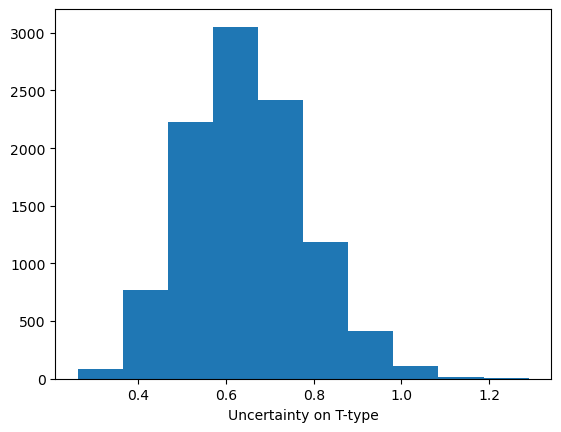

In [24]:
plt.hist(DRP_table['DL_ttype_err'])
plt.xlabel('Uncertainty on T-type')

Text(0.5, 0, 'P(S0)')

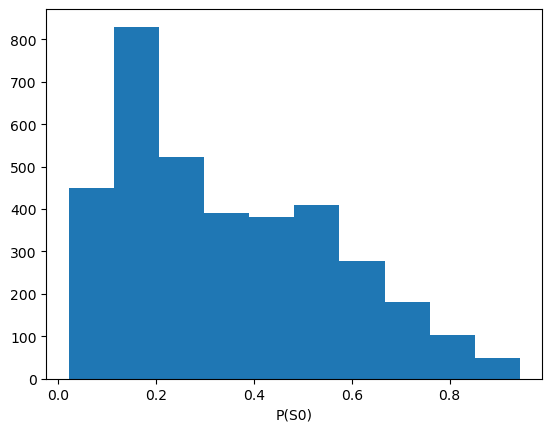

In [25]:
plt.hist(DRP_table['DL_P_S0'][(DRP_table['DL_ttype'] < 0)])
plt.xlabel('P(S0)')

## define lenticular galaxy sample
* T-type = 0 within error
* T-type < 0 with P(S0) > 0.5
* not in elliptical or spiral sample
* stellar map passes gradient smoothness requirement for spirals

In [29]:
## spiral sample
spiral_mask = DRP_table['M_R90'] > 0

## elliptical sample
elliptical_mask = DRP_table['Mvir'] > 0

DRP_table['S0'] = np.zeros(len(DRP_table), dtype='int')

for i in range(len(DRP_table)):

    if  not spiral_mask[i] and not elliptical_mask[i]:

        ## check for ttype err
        if np.abs(DRP_table['DL_ttype'][i]) - DRP_table['DL_ttype_err'][i] <= 0:

            DRP_table['S0'][i] = 1

        ## check for P(S0)
        elif DRP_table['DL_ttype'][i] <= 0 and DRP_table['DL_P_S0'][i] >= 0.5:
            
            DRP_table['S0'][i] = 1

In [32]:
# number of starting lenticular sample
len(DRP_table[DRP_table['S0']==1])

757

## fit one lenticular galaxy

In [33]:
DRP_table[DRP_table['S0']==1]

plate,ifudsgn,plateifu,mangaid,versdrp2,versdrp3,verscore,versutil,versprim,platetyp,srvymode,objra,objdec,ifuglon,ifuglat,ifura,ifudec,ebvgal,nexp,exptime,drp3qual,bluesn2,redsn2,harname,frlplug,cartid,designid,cenra,cendec,airmsmin,airmsmed,airmsmax,seemin,seemed,seemax,transmin,transmed,transmax,mjdmin,mjdmed,mjdmax,gfwhm,rfwhm,ifwhm,zfwhm,mngtarg1,mngtarg2,mngtarg3,catidnum,plttarg,manga_tileid,nsa_iauname,ifudesignsize,ifutargetsize,ifudesignwrongsize,z,zmin,zmax,szmin,szmax,ezmin,ezmax,probs,pweight,psweight,psrweight,sweight,srweight,eweight,esweight,esrweight,nsa_field,nsa_run,nsa_camcol,nsa_version,nsa_nsaid,nsa_nsaid_v1b,nsa_z,nsa_zdist,nsa_sersic_absmag,nsa_elpetro_absmag,nsa_elpetro_amivar,nsa_sersic_mass,nsa_elpetro_mass,nsa_elpetro_ba,nsa_elpetro_phi,nsa_extinction,nsa_elpetro_th50_r,nsa_petro_th50,nsa_petro_flux,nsa_petro_flux_ivar,nsa_elpetro_flux,nsa_elpetro_flux_ivar,nsa_sersic_ba,nsa_sersic_n,nsa_sersic_phi,nsa_sersic_th50,nsa_sersic_flux,nsa_sersic_flux_ivar,smoothness_score,nsa_elpetro_th90,v_sys,v_sys_err,ba,ba_err,x0,x0_err,y0,y0_err,phi,phi_err,v_max,v_max_err,r_turn,r_turn_err,chi2,alpha,alpha_err,Rmax,M,M_err,fit_flag,Sigma_disk,Sigma_disk_err,R_disk,R_disk_err,rho_bulge,rho_bulge_err,R_bulge,R_bulge_err,M90_disk,M90_disk_err,M_disk,M_disk_err,chi2_disk,WF50,WF50_err,DL_ttype,vis_tidal,b,b_err,M_R90,M_R90_err,fit_function,A_g,A_r,logH2,R90_kpc,v_3p5,v_3p5_err,NSA_plate,NSA_fiberID,NSA_MJD,logH2_CG,logH2_CG_err,logH2_M,Z,Z_err,M_Z,M_Z_err,grad_Z,grad_Z_err,Z_0,Z_0_err,SFR,sSFR,SFR_err,sSFR_err,Flux_OII_3726,Flux_OII_3726_Err,Flux_OII_3728,Flux_OII_3728_Err,Flux_OIII_4958,Flux_OIII_4958_Err,Flux_OIII_5006,Flux_OIII_5006_Err,Flux_NII_6547,Flux_NII_6547_Err,Flux_NII_6583,Flux_NII_6583_Err,Flux_Ha_6562,Flux_Ha_6562_Err,Flux_Hb_4861,Flux_Hb_4861_Err,CMD_class,rabsmag_NSA,param_H2,param_H2_err,Z_map,Z_err_map,M_Z_map,M_Z_err_map,logHI_R90,Mvir,Mvir_err,star_sigma,star_sigma_err,dipole_moment,Rgal,vflag_VF,nsa_elpetro_log_mass,rabsmag,param_H2_R90,logHe,sphd_rho_c,sphd_rho_c_err,sphd_R_scale,sphd_R_scale_err,sphd_Sigma_d,sphd_Sigma_d_err,sphd_R_d,sphd_R_d_err,sphd_M_star,sphd_M_star_err,sphd_chi2,mhq_R_scale,mhq_R_scale_err,mhq_M_star,mhq_M_star_err,mhq_gamma,mhq_gamma_err,mhq_chi2,hq_R_scale,hq_R_scale_err,hq_M_star,hq_M_star_err,hq_chi2,sph_rho_c,sph_rho_c_err,sph_R_scale,sph_R_scale_err,sph_M_star,sph_M_star_err,sph_chi2,sum_M_star,sum_M_star_err,BPT_class,spiral_mask,elliptical_mask,Age_LW_Re_fit,Age_MW_Re_fit,ZH_LW_Re_fit,ZH_MW_Re_fit,M90_disk_h,M90_disk_err_h,sphd_M_star_err_h,sphd_M_star_h,V_R90,V_R90_err,e_M_star_R90,e_M_star_R90_err,e_M_star_R90_h,e_M_star_R90_err_h,v_eff,v_eff_err,logHI,logHI_err,HI_catalog,logHI_h,logHI_err_h,N2Ha,O3Hb,nsa_u_r,illustris_match,illustris_dist,illustris_u_r,illustris_Mstar,illustris_Mstar_Sal,illustris_Vmax,illustris_flag,illustris_MR90,MH2_S14_vol,MHI_S14_vol,MHtot,DL_ttype_err,DL_P_S0,DL_P_S0_err,S0
int64,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,bytes32,float64,float64,float64,float64,float64,float64,float64,int64,float64,int64,float64,float64,bytes53,int64,bytes32,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,float64,float64,float64,float64,int64,int64,int64,int64,bytes32,int64,bytes19,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,int64,bytes6,int64,int64,float64,float64,float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64,float64,float64[7],float64[7],float64[7],float64[7],float64,float64,float64,float64,float64[7],float64[7],float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,floa

In [36]:
test_gal = '10001-1902'

In [107]:
maps = extract_data(VEL_MAP_FOLDER, test_gal, ['Ha_vel', 'star_vel', 'r_band'])

In [108]:
mHa_vel = ma.array(maps['Ha_vel'], mask=maps['Ha_vel_mask'])
mstar_vel = ma.array(maps['star_vel'], mask=maps['star_vel_mask'])

Text(0.5, 1.0, 'H$\\alpha$ velocity map')

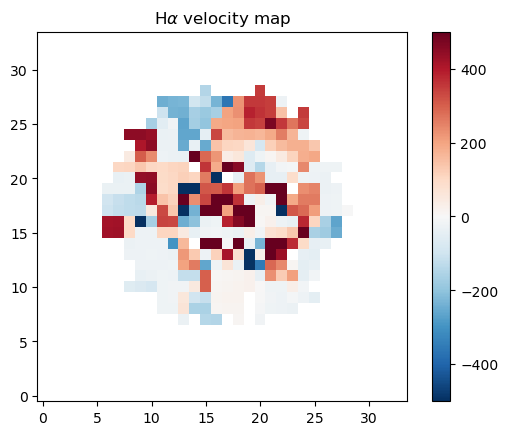

In [109]:
plt.imshow(mHa_vel, cmap='RdBu_r', vmin=-500, vmax=500, origin='lower')
plt.colorbar()
plt.title(r'H$\alpha$ velocity map')

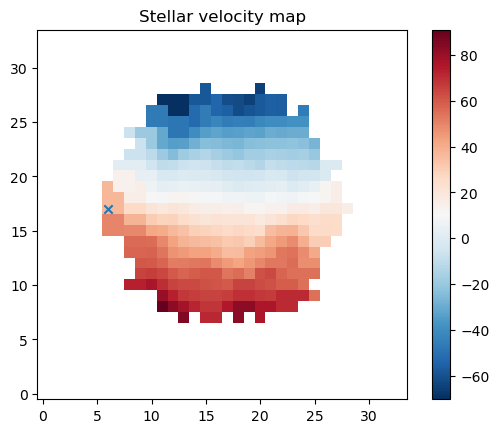

In [110]:
plt.imshow(mstar_vel, cmap='RdBu_r', origin='lower')
plt.colorbar()
plt.title(r'Stellar velocity map')
plt.scatter(6,17, marker='x')

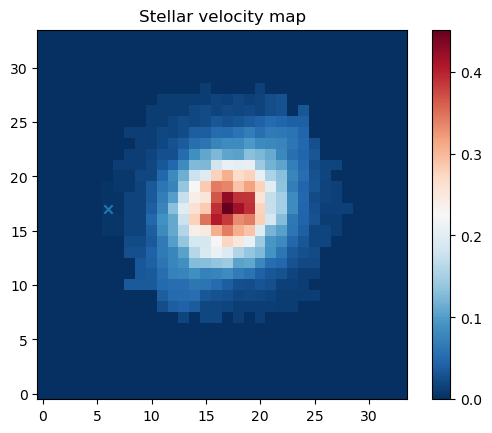

In [111]:
plt.imshow(maps['star_vel_ivar'], cmap='RdBu_r', origin='lower')
plt.colorbar()
plt.title(r'Stellar velocity map')
plt.scatter(6,17, marker='x')

## find a way to grab the clumps of binned data and turn it into a single data point

In [119]:
vels, counts = np.unique(mstar_vel, return_counts=1)
binned_vels = vels[counts>1]

In [120]:
binned_data = np.ones(mstar_vel.shape)*np.nan

for i in range(len(mstar_vel)):
    for j in range(len(mstar_vel)):

        if mstar_vel[i][j] in binned_vels:
            binned_data[i][j] = mstar_vel[i][j]

/var/folders/4q/zk1xkb454t7_ncsh3pf51p700000gp/T/ipykernel_52923/3414400529.py:7: UserWarning: Warning: converting a masked element to nan.
  binned_data[i][j] = mstar_vel[i][j]


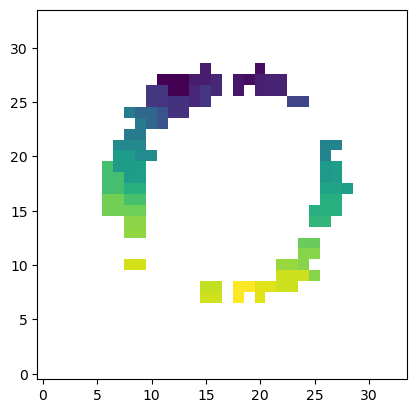

In [121]:
plt.imshow(binned_data, origin='lower')

In [122]:
for i in range(0,1):

    vel = binned_vels[0]
    print(vel)
    # find the positions of all the data points with a given velocity

    mask = binned_data == vel

    temp_array = np.ones(binned_data.shape)
    temp_array[~mask] = 0

-70.3631


In [123]:
ndimage.center_of_mass(temp_array)

(26.6, 12.2)

## fitting

In [138]:
# get parameters we need
i_DRP = DRP_dict[test_gal]
z = DRP_table['nsa_z'][i_DRP]
R90 = DRP_table['nsa_elpetro_th90'][i_DRP]
axis_ratio = DRP_table['nsa_elpetro_ba'][i_DRP]
phi_EofN_deg = DRP_table['nsa_elpetro_phi'][i_DRP]

In [139]:
mr_band = ma.array(maps['r_band'], mask=maps['star_vel_mask'])
center_guess = np.unravel_index(ma.argmax(mr_band), mr_band.shape)
i_center_guess = center_guess[0]
j_center_guess = center_guess[1]
mvel = mstar_vel

sys_vel_guess = mstar_vel[center_guess]

if (sys_vel_guess is ma.masked):
        
    sys_vel_guess = 0.

In [140]:
q0 = 0.2
cosi2 = (axis_ratio**2 - q0**2)/(1 - q0**2)

if cosi2 < 0:
    cosi2 = 0.001
#    inclination_angle_guess = np.arccos(np.sqrt(cosi2)) - 0.01
#else: 
inclination_angle_guess = np.arccos(np.sqrt(cosi2))

In [143]:
phi_guess = find_phi(center_guess, phi_EofN_deg, sys_vel_guess, mvel)
phi_guess = phi_guess%(2*np.pi)

2.68400223030192


In [153]:
### check if 95% of data is masked
len(mvel[mvel.mask])/len(np.ndarray.flatten(mvel)) > 0.95

False

In [157]:
### try the actual fitting

dist_to_galaxy_Mpc = c*z/H_0
dist_to_galaxy_kpc = dist_to_galaxy_Mpc*1000


pix_scale_factor = dist_to_galaxy_kpc*np.tan(MANGA_SPAXEL_SIZE)

In [158]:
# vmax
v_max_index = np.unravel_index(ma.argmax(ma.abs(mvel)), mvel.shape)
v_max_guess = np.abs(mvel[v_max_index]/np.sin(inclination_angle_guess))
v_max_low = 10
v_max_high = 5100
v_max_bounds = (v_max_low, v_max_high)

In [159]:
#inclination

inclination_angle_low = np.max([0, inclination_angle_guess - np.radians(15)])
inclination_angle_high = np.min([inclination_angle_guess + np.radians(15), 0.5*np.pi])  
inclination_angle_bounds = (inclination_angle_low, inclination_angle_high)

In [161]:
 # Center coordinates
i_center_low = i_center_guess - 5
i_center_high = i_center_guess + 5
i_center_bounds = (i_center_low, i_center_high)

j_center_low = j_center_guess - 5
j_center_high = j_center_guess + 5
j_center_bounds = (j_center_low, j_center_high)

In [162]:
# Orientation angle
phi_low = 0
phi_high = 2*np.pi + 0.1
phi_bounds = (phi_low, phi_high)

In [163]:
# Turn radius [kpc]
r_turn_low = 0.01
r_turn_high = 100
r_turn_bounds = (r_turn_low, r_turn_high)

In [164]:
if v_max_guess > v_max_high:

    v_max_guess = 1000

In [166]:
############################################################################
# Set the initial guess for r_turn to be equal to half of the radius where
# the maximum velocity occurs
#---------------------------------------------------------------------------
center_guess = (i_center_guess, j_center_guess)

r_turn_guess_spaxels,_ = deproject_spaxel(v_max_index,
                                          center_guess,
                                          phi_guess,
                                          inclination_angle_guess)

r_turn_guess_kpc = 0.5*r_turn_guess_spaxels*pix_scale_factor

if r_turn_guess_kpc < r_turn_low:
    r_turn_guess_kpc = 1.1*r_turn_low
if r_turn_guess_kpc > r_turn_high:
    r_turn_guess_kpc = 0.9*r_turn_high

In [167]:
# Alpha
alpha_guess = 2
alpha_low = 0.001
alpha_high = 100
alpha_bounds = (alpha_low, alpha_high)

In [171]:
# Systemic velocity
sys_vel_low = -1100
sys_vel_high = 1100
sys_vel_bounds = (sys_vel_low, sys_vel_high)

In [172]:
# Parameter guesses
vel_guesses = [v_max_guess, \
               r_turn_guess_kpc, \
               alpha_guess]
pos_guesses = [sys_vel_guess, \
               inclination_angle_guess, \
               i_center_guess, \
               j_center_guess, \
               phi_guess]
# Parameter bounds
vel_bounds = [v_max_bounds, \
              r_turn_bounds, \
              alpha_bounds]
pos_bounds = [sys_vel_bounds, \
              inclination_angle_bounds, \
              i_center_bounds, \
              j_center_bounds, \
              phi_bounds]

In [173]:
print('pos guesses:', pos_guesses)
print('pos bounds:', pos_bounds)
print('vel_guesses:', vel_guesses)
print('vel_bounds:', vel_bounds)

pos guesses: [14.286364, 0.5869687736345583, 17, 17, 2.68400223030192]
pos bounds: [(-1100, 1100), (0.32516938583540894, 0.8487681614337077), (12, 22), (12, 22), (0, 6.383185307179586)]
vel_guesses: [164.42465756584897, 1.0016715741858842, 2]
vel_bounds: [(10, 5100), (0.01, 100), (0.001, 100)]


In [191]:
mvel_ivar = ma.array(maps['star_vel_ivar'], mask=maps['star_vel_mask'])

In [198]:
### take the stellar velocity map and split into binned and non-binned parts
unbinned = np.ones(mvel.shape)*np.nan
binned = np.ones(mvel.shape)*np.nan
unbinned_ivar = np.ones(mvel.shape)*np.nan
binned_ivar = np.ones(mvel.shape)*np.nan


unique_vels, counts = np.unique(mvel, return_counts=1)
binned_vels = unique_vels[counts>1]
binned_vels = binned_vels[~binned_vels.mask]


for i in range(len(mvel)):
    for j in range(len(mvel)):

        if mvel[i][j] in binned_vels:

            binned[i][j] = mvel[i][j]
            binned_ivar[i][j] = mvel_ivar[i][j]

        else:
            unbinned[i][j] = mvel[i][j]
            unbinned_ivar[i][j] = mvel_ivar[i][j]


/var/folders/4q/zk1xkb454t7_ncsh3pf51p700000gp/T/ipykernel_52923/3866417602.py:22: UserWarning: Warning: converting a masked element to nan.
  unbinned[i][j] = mvel[i][j]
/var/folders/4q/zk1xkb454t7_ncsh3pf51p700000gp/T/ipykernel_52923/3866417602.py:23: UserWarning: Warning: converting a masked element to nan.
  unbinned_ivar[i][j] = mvel_ivar[i][j]


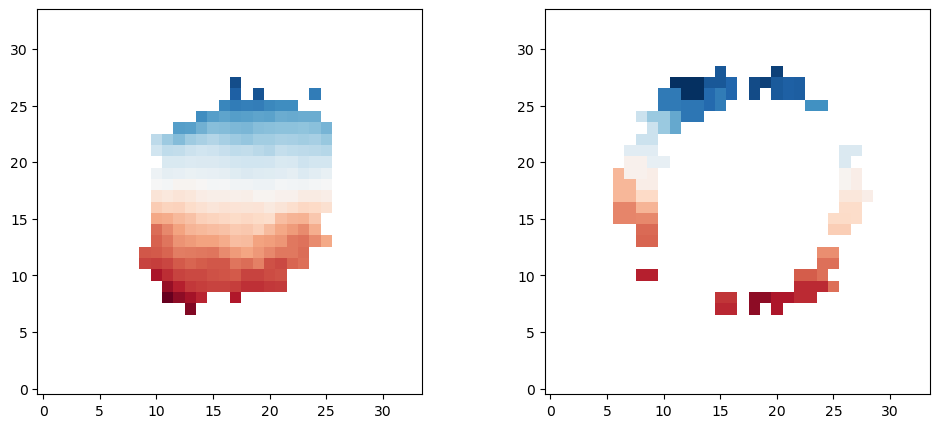

In [199]:
fig, ax = plt.subplots(1,2, figsize=(12,5))
maxvel = ma.max(mvel)
minvel = ma.min(mvel)
ax[0].imshow(unbinned, cmap='RdBu_r', origin='lower', vmin=minvel, vmax=maxvel)
ax[1].imshow(binned, cmap='RdBu_r', origin='lower', vmin=minvel, vmax=maxvel)

In [200]:
### flatten the unbinned part
mvel_flat = mvel.compressed()
mvel_ivar_flat = mvel_ivar.compressed()


In [206]:
### convert the binned map into data points using strategy like HI vel 'tail' fit

r_com = []
v_com = []

for i in range(0,1):

    vel = binned_vels[0]
    print(vel)
    # find the positions of all the data points with a given velocity
    
    mask = binned_data == vel
    
    com = ndimage.center_of_mass(mask)
    print(com)

    r_com.append(deproject_spaxel(com, center_guess, phi_guess, inclination_angle_guess))
    v_com.append(vel)

-70.3631
(26.6, 12.2)


In [207]:
r_com

[(12.145968841896684, -2.1346877199169283)]

In [208]:
v_com

[-70.3631]